# 01 · PlantNet-300K's class distribution, with ASPCA overlaid

PlantNet-300K's own README calls out "strong class imbalance" as a defining
property of the dataset. This notebook looks at that distribution directly,
and marks which of its 1000 species have any cat-toxicity information at
all: an **exact** match in `data/raw/aspca/cats_plant_details.json` (same
genus *and* species), a **genus-only** match (a relative is listed, not
necessarily the same species), or **no match**, split further by whether
the matched ASPCA entry says toxic or non-toxic to cats.

Matching is always by scientific name (`species_match.SpeciesIndex`, new in
this project) - never by common name, to avoid the "lily problem" (*Lilium*,
*Hemerocallis*, *Hippeastrum* and *Spathiphyllum* are all called "lily" in
English and are four different genera with different toxicity).

Contents: 1 Load and match · 2 The class-size distribution · 3 Organ mix ·
4 How sparse are the matched classes · 5 A taxonomy graph · 6 A genus-fallback
toxicity lookup · 7 Take-aways

## 1 · Load and match

`plantnet300K_metadata.csv` is per-*image* (one row per photo, 306,087 rows);
`species_metadata.csv` is per-*species* (1000 rows, with genus/epithet/family
already parsed). `cats_plant_details.json` is the 982-plant ASPCA detail
scrape from earlier in this project.

In [1]:
import collections
import csv
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plant_toxicity_checker.config import DATASET_DIR
from plant_toxicity_checker.species_match import (
    SpeciesIndex,
    parse_scientific_name,
)

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

PLANTNET_DIR = DATASET_DIR / "plantnet"

with open(PLANTNET_DIR / "species_metadata.csv", encoding="utf-8") as f:
    pn_species = list(csv.DictReader(f))

image_counts = collections.Counter()
organ_counts = collections.Counter()
with open(PLANTNET_DIR / "plantnet300K_metadata.csv", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        image_counts[row["species_id"]] += 1
        organ_counts[row["organ"]] += 1

for row in pn_species:
    row["n_images"] = image_counts[row["species_id"]]

print(f"{len(pn_species)} PlantNet species, {sum(image_counts.values())} images")

1000 PlantNet species, 306087 images


In [2]:
aspca = json.load(open(DATASET_DIR / "aspca" / "cats_plant_details.json", encoding="utf-8"))["plants"]

# ASPCA -> PlantNet direction (dataset coverage, this notebook's main use)
pn_index = SpeciesIndex.from_rows(
    pn_species, genus_of=lambda r: r["genus"], epithet_of=lambda r: r["epithet"]
)

# PlantNet -> ASPCA direction (species_id -> toxicity lookup, section 6)
aspca_index = SpeciesIndex.from_rows(
    aspca,
    genus_of=lambda p: (parse_scientific_name(p["scientific_name"].split(",")[0]) or (None,))[0],
    epithet_of=lambda p: (parse_scientific_name(p["scientific_name"].split(",")[0]) or (None, None))[1],
)


def cats_status(aspca_entry):
    if "cats" in aspca_entry["toxic_to"]:
        return "toxic"
    if "cats" in aspca_entry["non_toxic_to"]:
        return "non_toxic"
    return "unknown"


# tag every PlantNet species with its match against ASPCA
for row in pn_species:
    sci = f"{row['genus']} {row['epithet']}".strip()
    result = aspca_index.match(sci)
    row["match"] = result.status
    if result.status == "exact":
        row["cats_status"] = cats_status(result.exact_row)
    elif result.status == "genus_only":
        statuses = {cats_status(p) for p in result.genus_candidates}
        row["cats_status"] = "mixed" if len(statuses) > 1 else next(iter(statuses))
    else:
        row["cats_status"] = None

CATEGORY = {
    ("exact", "toxic"): "exact - toxic", ("exact", "non_toxic"): "exact - non-toxic",
    ("genus_only", "toxic"): "genus - toxic", ("genus_only", "non_toxic"): "genus - non-toxic",
    ("genus_only", "mixed"): "genus - mixed",   # the genus has both toxic and non-toxic ASPCA entries
}
for row in pn_species:
    row["category"] = CATEGORY[(row["match"], row["cats_status"])] if row["match"] != "none" else "no match"

print(pd.Series([r["category"] for r in pn_species]).value_counts())

no match             726
genus - non-toxic    135
genus - toxic        105
exact - non-toxic     28
exact - toxic          6
Name: count, dtype: int64


## 2 · The class-size distribution

Sorted, log scale (the only way this is readable: sizes span 4 to 9010
images). Each of the 1000 species is one point; colour is the ASPCA match
category from section 1. If PlantNet's abundant classes and its
ASPCA-matched classes were unrelated, matched points would scatter evenly
across the curve; if they cluster on the left (common) side, the species
ASPCA happens to know about are the ones PlantNet happens to have a lot of
photos of.

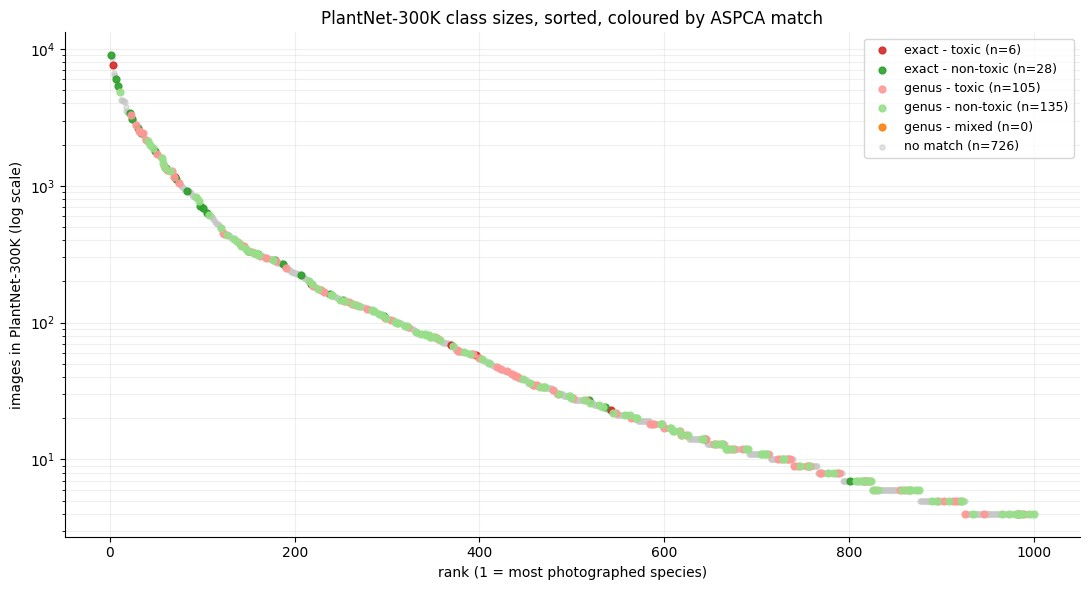

whole dataset:  mean=306  median=28
exact - toxic      n=   6  mean= 1528.3  median=   130
exact - non-toxic  n=  28  mean= 1468.1  median=   482
genus - toxic      n= 105  mean=  284.5  median=    32
genus - non-toxic  n= 135  mean=  208.3  median=    27
no match           n= 726  mean=  272.5  median=    27


In [3]:
COLORS = {
    "exact - toxic": "#d62728", "exact - non-toxic": "#2ca02c",
    "genus - toxic": "#ff9896", "genus - non-toxic": "#98df8a",
    "genus - mixed": "#ff7f0e", "no match": "#c7c7c7",
}
ORDER = list(COLORS)

sizes_sorted = sorted(pn_species, key=lambda r: -r["n_images"])
ranks = np.arange(1, len(sizes_sorted) + 1)

fig, ax = plt.subplots(figsize=(11, 6))
for cat in ORDER:
    xs = [i + 1 for i, r in enumerate(sizes_sorted) if r["category"] == cat]
    ys = [sizes_sorted[i - 1]["n_images"] for i in xs]
    ax.scatter(xs, ys, s=14 if cat == "no match" else 24, color=COLORS[cat], label=f"{cat} (n={len(xs)})",
              alpha=0.5 if cat == "no match" else 0.9, zorder=2 if cat == "no match" else 3)
ax.set_yscale("log")
ax.set_xlabel("rank (1 = most photographed species)")
ax.set_ylabel("images in PlantNet-300K (log scale)")
ax.set_title("PlantNet-300K class sizes, sorted, coloured by ASPCA match")
ax.legend(fontsize=9, loc="upper right")
ax.grid(alpha=0.2, which="both")
plt.tight_layout()
plt.show()

print(f"whole dataset:  mean={np.mean([r['n_images'] for r in pn_species]):.0f}  "
      f"median={np.median([r['n_images'] for r in pn_species]):.0f}")
for cat in ("exact - toxic", "exact - non-toxic", "genus - toxic", "genus - non-toxic", "no match"):
    vals = [r["n_images"] for r in pn_species if r["category"] == cat]
    if vals:
        print(f"{cat:<18} n={len(vals):4d}  mean={np.mean(vals):7.1f}  median={np.median(vals):6.0f}")
for extra in ("genus - mixed",):
    vals = [r["n_images"] for r in pn_species if r["category"] == extra]
    if vals:
        print(f"{extra:<18} n={len(vals):4d}  mean={np.mean(vals):7.1f}  median={np.median(vals):6.0f}")

## 3 · Organ mix

Species-level counts hide what the photos are actually *of*. PlantNet mixes
several organs per species - a model trained on all of them is learning
"recognise this species from any part", not specifically "from a flower",
which is what a single-plant photo typically gives it.

In [4]:
organ_df = pd.Series(organ_counts).sort_values(ascending=False)
organ_df = pd.DataFrame({"images": organ_df, "share": (organ_df / organ_df.sum() * 100).round(1)})
organ_df

,images,share
flower,176501,57.7
leaf,110760,36.2
fruit,11275,3.7
habit,4442,1.5
bark,2076,0.7
other,993,0.3
branch,37,0.0
scan,2,0.0
none,1,0.0


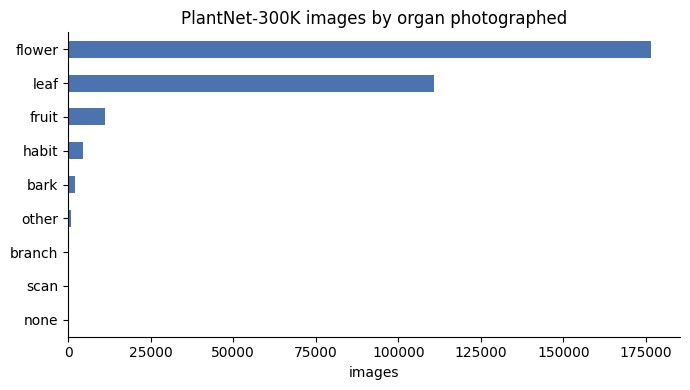

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
organ_df["images"].plot.barh(ax=ax, color="#4c72b0")
ax.set_xlabel("images")
ax.set_title("PlantNet-300K images by organ photographed")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4 · How sparse are the matched classes?

A species can be an "exact match" and still have too few images to train a
reliable class on its own. Flagging anything under 20 images (a common
rough floor for a from-scratch class; a kNN/embedding approach like the one
already used for Oxford-102 is more forgiving, but still weaker with very
few examples).

In [6]:
SPARSE_FLOOR = 20
sparse_overall = sum(1 for r in pn_species if r["n_images"] < SPARSE_FLOOR)
print(f"{sparse_overall}/{len(pn_species)} PlantNet species overall have fewer than {SPARSE_FLOOR} images")

matched = [r for r in pn_species if r["match"] in ("exact", "genus_only")]
sparse_matched = [r for r in matched if r["n_images"] < SPARSE_FLOOR]
print(f"{len(sparse_matched)}/{len(matched)} ASPCA-matched species have fewer than {SPARSE_FLOOR} images")
print()
cols = ["full_species", "genus", "match", "cats_status", "n_images"]
pd.DataFrame(sorted(sparse_matched, key=lambda r: r["n_images"]))[cols].head(15)

429/1000 PlantNet species overall have fewer than 20 images
109/274 ASPCA-matched species have fewer than 20 images



,full_species,genus,match,cats_status,n_images
0,Pelargonium capitatum (L.) L'Hér.,Pelargonium,genus_only,toxic,4
1,Cymbalaria hepaticifolia (Poir.) Wettst.,Cymbalaria,genus_only,non_toxic,4
2,Anthurium scandens (Aubl.) Engl.,Anthurium,genus_only,toxic,4
3,Peperomia dolabriformis Kunth,Peperomia,genus_only,non_toxic,4
4,Smilax china L.,Smilax,genus_only,non_toxic,4
5,Sedum moranense Kunth,Sedum,genus_only,non_toxic,4
6,Sedum niveum Davidson,Sedum,genus_only,non_toxic,4
7,Smilax laurifolia L.,Smilax,exact,non_toxic,4
8,Tradescantia crassifolia Cav.,Tradescantia,genus_only,toxic,4
9,Calochortus eurycarpus S.Watson,Calochortus,genus_only,non_toxic,4


## 5 · A taxonomy graph

A Family -> Genus tree over the union of PlantNet's genera and ASPCA's
matched genera. Genus node colour is the ASPCA match category (same as
section 2); size is the total PlantNet images in that genus. This is the
same structure a "genus fallback" toxicity lookup would walk at inference
time (section 6) - shown here as a picture instead of a lookup.

Restricted to genera that appear in PlantNet (showing all ~300 of ASPCA's
*non*-PlantNet genera too would be unreadable and wouldn't help - they have
no photos to classify against yet anyway).

In [7]:
import networkx as nx

genus_rows = collections.defaultdict(list)
for row in pn_species:
    genus_rows[row["genus"]].append(row)

graph = nx.Graph()
for genus, rows in genus_rows.items():
    family = rows[0]["family"] or "(unknown family)"
    total_images = sum(r["n_images"] for r in rows)
    cats = {r["category"] for r in rows}
    # a genus can contain more than one matched species with different
    # verdicts (rare) - if so it is shown as the more cautious one
    for cat in ("exact - toxic", "genus - mixed", "genus - toxic", "exact - non-toxic", "genus - non-toxic", "no match"):
        if cat in cats:
            genus_category = cat
            break
    graph.add_node(("genus", genus), kind="genus", category=genus_category, size=total_images)
    graph.add_node(("family", family), kind="family")
    graph.add_edge(("family", family), ("genus", genus))

print(f"{graph.number_of_nodes()} nodes ({len(genus_rows)} genera + "
      f"{graph.number_of_nodes() - len(genus_rows)} families), {graph.number_of_edges()} edges")

436 nodes (325 genera + 111 families), 325 edges


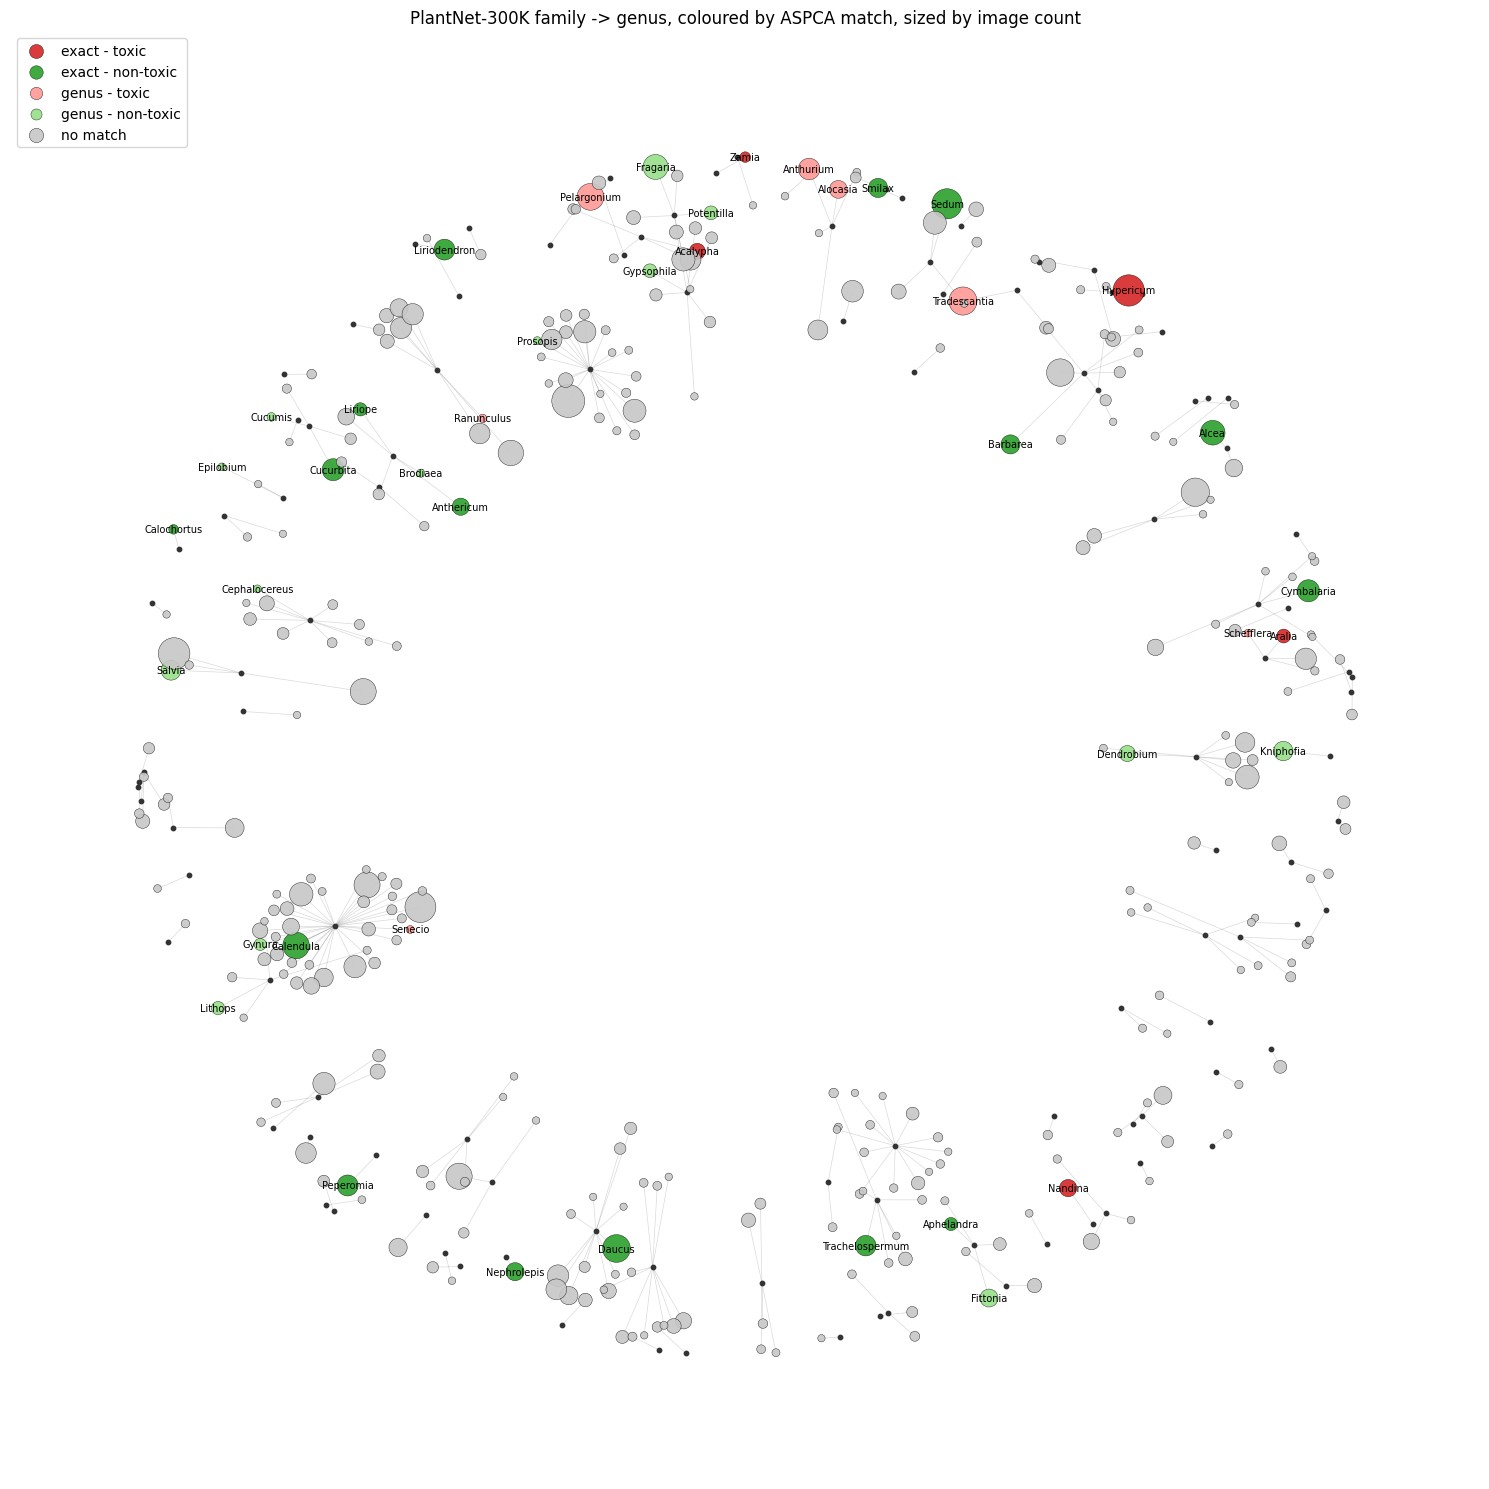

In [8]:
pos = nx.spring_layout(graph, k=0.35, seed=0, iterations=200)

fig, ax = plt.subplots(figsize=(15, 15))
family_nodes = [n for n in graph if n[0] == "family"]
nx.draw_networkx_nodes(graph, pos, nodelist=family_nodes, node_size=10, node_color="#333333", ax=ax)

for cat, color in COLORS.items():
    nodes = [n for n in graph if n[0] == "genus" and graph.nodes[n]["category"] == cat]
    sizes = [20 + 4 * np.sqrt(graph.nodes[n]["size"]) for n in nodes]
    nx.draw_networkx_nodes(graph, pos, nodelist=nodes, node_size=sizes, node_color=color,
                           edgecolors="black", linewidths=0.3, alpha=0.9, ax=ax, label=cat)

nx.draw_networkx_edges(graph, pos, alpha=0.15, width=0.5, ax=ax)

# label only the ASPCA-matched genera - labelling all ~300 genera would be unreadable
label_nodes = {n: n[1] for n in graph if n[0] == "genus" and graph.nodes[n]["category"] != "no match"}
nx.draw_networkx_labels(graph, pos, labels=label_nodes, font_size=7, ax=ax)

ax.set_title("PlantNet-300K family -> genus, coloured by ASPCA match, sized by image count")
ax.legend(fontsize=10, loc="upper left", markerscale=0.6)
ax.axis("off")
plt.tight_layout()
plt.show()

## 6 · A genus-fallback toxicity lookup

The same `SpeciesIndex`, built the other way round (from ASPCA, matched
*against*), is directly the lookup a real verdict function would use: given
a species a classifier names, look it up by scientific name; exact match ->
its own verdict; genus match -> flag it as a caution from a relative,
**never** a "safe" (matches this project's existing rule: safety is never
inferred from a related plant; toxicity caution may be).

In [9]:
def lookup(scientific_name):
    result = aspca_index.match(scientific_name)
    if result.status == "exact":
        p = result.exact_row
        verdict = "TOXIC to cats" if "cats" in p["toxic_to"] else (
            "non-toxic to cats" if "cats" in p["non_toxic_to"] else "unknown for cats")
        return f"{scientific_name}: {verdict} (ASPCA: {p['name']})"
    if result.status == "genus_only":
        toxic_relatives = [p["name"] for p in result.genus_candidates if "cats" in p["toxic_to"]]
        if toxic_relatives:
            return (f"{scientific_name}: COULD BE TOXIC - related species in the same genus "
                    f"({', '.join(toxic_relatives[:3])}) are toxic to cats. Treat as unknown/caution.")
        return (f"{scientific_name}: unknown for cats - the genus is on ASPCA's list but only as "
                "non-toxic relatives, never inferred safe from those alone.")
    return f"{scientific_name}: unknown - genus not found on ASPCA's list at all"


for example in ("Rosa canina", "Anthericum liliago", "Lilium bulbiferum", "Hypericum perforatum",
                "Quercus robur"):
    print(lookup(example))
    print()

Rosa canina: unknown for cats - the genus is on ASPCA's list but only as non-toxic relatives, never inferred safe from those alone.

Anthericum liliago: non-toxic to cats (ASPCA: Saint Bernards Lily)

Lilium bulbiferum: COULD BE TOXIC - related species in the same genus (Asian Lily, Easter Lily, Japanese Show Lily) are toxic to cats. Treat as unknown/caution.

Hypericum perforatum: TOXIC to cats (ASPCA: St. John’s Wort)

Quercus robur: unknown - genus not found on ASPCA's list at all



## 7 · Take-aways

**Class imbalance is exactly as severe as PlantNet's own README warns.**
Mean 306 images/species, median 28 - a small number of very common species
pull the mean far above what a typical class actually has. 429 of the 1000
species (43%) have fewer than 20 images at all, regardless of ASPCA
relevance.

**ASPCA's exact matches are not a random sample of PlantNet - they're
biased toward the abundant end.** The scatter in section 2 shows this
directly: the 6 exact-toxic and 28 exact-non-toxic points cluster on the
left (common) side of the curve, at roughly 5x the dataset's mean class
size. That is not a coincidence: the species that happen to be both
catalogued by ASPCA *and* heavily photographed by PlantNet's citizen
scientists are the common, easily-recognised ones - abundant weeds and
garden escapees. Genus-only matches show no such bias (mean/median close to
the whole dataset's) - matching a genus, not a species, pulls in whatever
happens to share that name, not specifically the well-photographed member.

**Being toxicity-relevant does not protect a class from being too sparse to
train.** 109 of the 274 ASPCA-matched species (40%) still fall under the
20-image floor - some down to 4, the same minimum as the dataset overall.
Section 4's table is the concrete list to look at before deciding whether to
exclude, oversample, or lean on genus-pooled candidates for these.

**The organ mix matters for what "train on PlantNet" actually teaches a
model.** 57.7% flower, 36.2% leaf, the rest scattered. A model trained on
all of it is learning "recognise this species from any part shown", not
specifically "from a flower" - worth a deliberate decision (filter to
`organ == "flower"`, or keep it mixed and accept the model saw leaves too)
before training, not an accident of what happened to be in the CSV.

**The taxonomy graph and the genus-fallback lookup work as intended.** The
lily example from earlier in this project's discussion is now a real,
working case, not a hypothetical: `Lilium bulbiferum` (a PlantNet species
with no exact ASPCA entry) correctly resolves to "COULD BE TOXIC - related
species in the same genus (Asian Lily, Easter Lily, Japanese Show Lily) are
toxic to cats" - toxicity escalates from a relative, but `Rosa canina`
(genus known only via *non-toxic* relatives) correctly refuses to say safe,
landing on "unknown ... never inferred safe from those alone" instead. Both
match the safety rule this project has used throughout.

**One real edge case found while building this: 3 genera are genuinely
mixed.** *Aloe*, *Cordyline* and *Ipomoea* each have both toxic and
non-toxic ASPCA entries within the same genus (none of PlantNet's 1000
species happen to land in exactly those 3 genera, so it didn't show up in
the plot here, but the `SpeciesIndex`/lookup code handles it correctly: a
genus match with any toxic relative is flagged cautious, even if the
queried species happens to be a non-toxic member of that same mixed genus -
the conservative direction, and the right one).

**Before training:** decide a minimum-images-per-class policy (exclude
under some floor, or fold sparse species into their genus for a coarser
target), decide on the organ question above, and note that this whole
analysis used PlantNet-300K specifically - the same `species_match` code
would need re-running against PlantCLEF2024/iNaturalist's species tables if
one of those becomes the actual training set instead.